In [26]:
import os
import sys
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.lines import Line2D

import project_settings
importlib.reload(project_settings)
from project_settings import PATH_WRK, RESULTS_DIR

BLOCS = ["USA", "EU27", "RestOECD", "China", "RestBRICS", "RestAsia", "RoW"]
BLOC_MARKERS = {"USA": "o", "EU27": "s", "RestOECD": "^", "China": "D", "RestBRICS": "P", "RestAsia": "X", "RoW": "v"}
SCENARIO_COLORS = {"A": "#1f77b4", "B": "#ff7f0e"}
MODEL_LABELS = {2: "model 2 (D / F)", 3: "model 3 (X / I)", 4: "model 4 (4 channels)"}
SCENARIO_LABELS = {"A": "scenario A", "B": "scenario B"}


In [27]:
def export_graph(plot, path, dpi=300):

    if isinstance(plot, tuple):
        fig = plot[0]
    elif isinstance(plot, Figure):
        fig = plot
    else:
        fig = plot.figure

    folder = os.path.dirname(path)
    if folder:
        os.makedirs(folder, exist_ok=True)

    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    return path


def load_choc(base, content, year, model, choc_files=("A", "B"), folder=None):
    folder = folder or f"{RESULTS_DIR}choc_tfp/{base}/"
    frames = []
    for s in choc_files:
        path = f"{folder}resultats{model}_blocs_{base}_{content}_{year}_choc{s}.csv"
        if not os.path.exists(path):
            print(f"[skipped] no results file: {path}")
            continue
        frames.append(pd.read_csv(path))
    if not frames:
        raise FileNotFoundError(f"no results file for {base} / {content} / {year} / model {model} in {folder}")
    return pd.concat(frames, ignore_index=True).drop_duplicates(["bloc", "sector", "scenario"])


def plot_choc(df, sectors, blocs=BLOCS, scenarios=("A", "B"), model=2, title=None, figsize=(10,8),
              jitter=0.07, seed=0, y_min=None, y_max=None):
    rng = np.random.default_rng(seed)
    missing = [s for s in sectors if s not in set(df["sector"])]
    if missing:
        print(f"[plot_choc] sectors not in the results, left out: {missing}")
    sectors = [s for s in sectors if s not in missing]
    if y_min is not None:
        df = df[df["dlnCost"] >= y_min]
    if y_max is not None:
        df = df[df["dlnCost"] <= y_max]
    n_sc = len(scenarios)
    slot = 0.8 / n_sc
    box_width = slot * 0.8
    if title is None:
        title = "Change in unit cost (dlnCost) by sector, coalition block and scenario"
    title = f"{title}\n{MODEL_LABELS[model]}"

    fig, ax = plt.subplots(figsize=figsize or (max(8.0, 0.6 * len(sectors) * n_sc / 2 + 3), 6))
    xticks, xticklabels = [], []

    for si, sector in enumerate(sectors):
        ax.text(si, -0.1, sector, transform=ax.get_xaxis_transform(), ha="right", va="top", fontsize=10, fontweight="bold", rotation=45)
        for k, scenario in enumerate(scenarios):
            center = si + (k - (n_sc - 1) / 2) * slot
            xticks.append(center)
            xticklabels.append(scenario)
            sub = df[(df["sector"] == sector) & (df["scenario"] == scenario) & df["bloc"].isin(blocs)]
            if sub.empty:
                continue
            ax.boxplot(
                sub["dlnCost"].values, positions=[center], widths=box_width,
                showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="none", edgecolor="black", linewidth=1),
                medianprops=dict(color="black"), whiskerprops=dict(color="black"),
                capprops=dict(color="black"), zorder=2,
            )
            for bloc in blocs:
                pts = sub[sub["bloc"] == bloc]
                if pts.empty:
                    continue
                ax.scatter(center + rng.uniform(-jitter, jitter, size=len(pts)), pts["dlnCost"],
                           color=SCENARIO_COLORS[scenario], marker=BLOC_MARKERS[bloc], s=60, zorder=3,
                           edgecolors="black", linewidths=0.5, label="_nolegend_")

    ax.axhline(0, color="black", linewidth=0.7, linestyle="--", zorder=0)
    for k in range(1, len(sectors)):
        ax.axvline(k - 0.5, color="gray", linestyle=":", linewidth=0.8, alpha=0.6, zorder=0)
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels, fontsize=9)
    ax.set_xlim(-0.5, len(sectors) - 0.5)
    ax.set_ylabel("dlnCost (change in log unit cost vs baseline: 0.01 = about +1 %)")
    ax.set_title(title)

    legend_handles = (
        [Line2D([0], [0], marker="s", color="none", markerfacecolor=SCENARIO_COLORS[s], markeredgecolor="black",
                markersize=9, label=SCENARIO_LABELS[s]) for s in scenarios]
        + [Line2D([0], [0], marker=BLOC_MARKERS[b], color="none", markerfacecolor="white", markeredgecolor="black",
                  markersize=9, label=b) for b in blocs]
    )
    ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=5)
    fig.tight_layout()
    return fig, ax


In [28]:
BASE = "GTAP"
CONTENT = "dir"             # "dir" : rd_dir_CI | "tot" : rd_tot_CI
YEAR = 2020
MODEL = 2                   # 2, 3, or 4
CHOC_FILES = ["B"]
SCENARIOS = ["A", "B"]


# "A", "B", "C", "C10_C12", "C13_C15", "C16_C18", "C19", "C20+C21", "C22", "C23", "C24", "C25", "C26", "C27", "C28", "C29", "C30", "C31_C33", "D", "E", "F", "G", "H49", "H50", "H51", "H52", "H53+J", "I", "K", "L", "M+N", "O+U", "P", "Q", "R+S+T"
SECTORS = ["C", "C10_C12", "C13_C15", "C16_C18", "C19", "C20+C21", "C22", "C23", "C24", "C25", "C26", "C27", "C28", "C29", "C30", "C31_C33"]
BLOCS_TO_PLOT = BLOCS      # Or select a subset, for example ["USA", "EU27", "China"]

#df_choc = load_choc(BASE, CONTENT, YEAR, MODEL, CHOC_FILES)
#fig, ax = plot_choc(df_choc, SECTORS, BLOCS_TO_PLOT, SCENARIOS, MODEL)
#export_graph((fig, ax), RESULTS_DIR + f"graphs/choc_dlnCost_{BASE}_{CONTENT}_{YEAR}_modele{MODEL}.png")
#plt.show()


In [29]:
# ---- Compare parameter variants for one NEMESIS scenario ---------------------------------------------
# Read resultats<model>_blocs_bilateral_<BASE>_<CONTENT>_horizon_<scenario><suffix>.csv
# produced by choc_tfp/choc_horizon.ipynb, one run per beta suffix.
# Run the following commands from the repository root, with code/ on PYTHONPATH:
# Reference estimates, unbounded:
#   python choc_tfp/make_beta.py --tag "" --upper none --lower none --suffix ""
# Reference estimates, clipped to [-0.25, 0]:
#   python choc_tfp/make_beta.py --tag "" --upper 0 --lower -0.25 --suffix _borne
# Year fixed effects, unbounded:
#   python choc_tfp/make_beta.py --tag _finetune --upper none --lower none --suffix _tendance
# Year fixed effects, clipped to [-0.25, 0]:
#   python choc_tfp/make_beta.py --tag _finetune --upper 0 --lower -0.25 --suffix _tendance_borne
# All selection, bound, and suffix options are explicit: do not infer the case from script defaults.
# Bounds clip the cross-database statistic after significance filtering; these are not constrained regressions.
# The historical suffix "tendance" denotes year fixed effects, not a linear time trend.
# In choc_horizon, select this NEMESIS_SCENARIO, the same BASE/CONTENT/MODEL, and each BETA_SUFFIX.
# CASES selects substitution assumptions A/B independently of the NEMESIS scenario and beta variant.
# Missing result versions are skipped. Running this graph notebook does not generate them.
NEMESIS_SCENARIO = "TariffsAndSub_grp1"
PLOT_YEAR = 2050            # year plotted (2025, 2030, ..., 2050)
BETA_VARIANTS = {           # title of the figure -> suffix of the beta files / results files
    "betas not bounded": "",
    "betas bounded (-0.25 to 0)": "_borne",
    "with trend, not bounded": "_tendance",
    "with trend, bounded (-0.25 to 0)": "_tendance_borne",
}


def load_horizon(base, content, scenario, suffix, model, year, folder=None):
    """Results of choc_horizon for one version of the betas, at one year: columns bloc, sector, scenario (= case A / B), dlnCost = sum over the supplying blocs.
    None if the file does not exist."""
    folder = folder or f"{RESULTS_DIR}choc_tfp/"
    path = f"{folder}resultats{model}_blocs_bilateral_{base}_{content}_horizon_{scenario}{suffix}.csv"
    if not os.path.exists(path):
        print(f"[skipped] no results file: {path}")
        return None
    df = pd.read_csv(path)
    if "dlnCost" not in df.columns:
        print(f"[skipped] no dlnCost in {path} (betas file missing when it was computed)")
        return None
    df = df[df["year"] == year]
    df = df.assign(dlnCost=df["dlnCost"].replace([np.inf, -np.inf], np.nan)).dropna(subset=["dlnCost"])     # rows without a finite cost change are left out
    df = df.groupby(["scenario", "bloc", "sector"], as_index=False)["dlnCost"].sum()                     # Sum origin contributions in logs to recover the sector total.
    if df.empty:
        print(f"[skipped] no row for {year} in {path}")
        return None
    return df

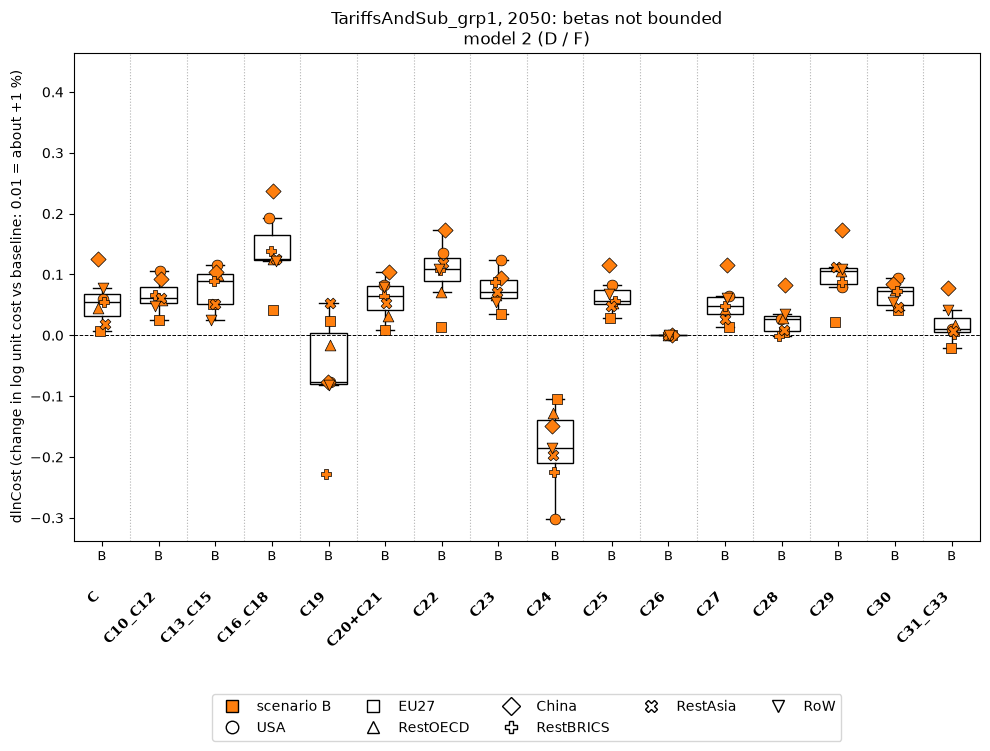

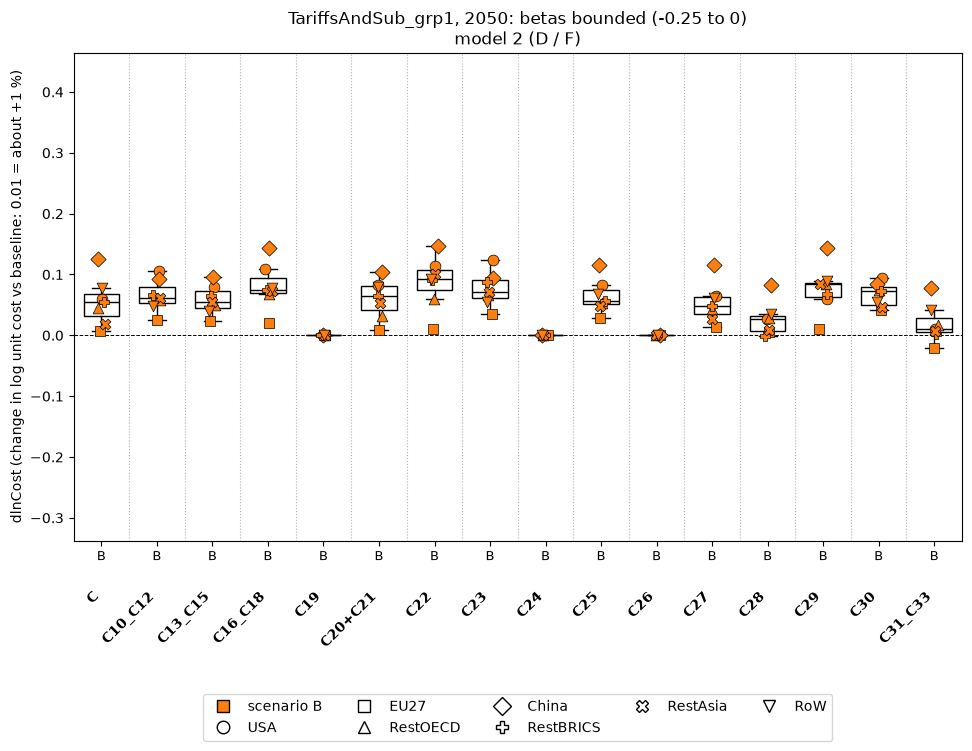

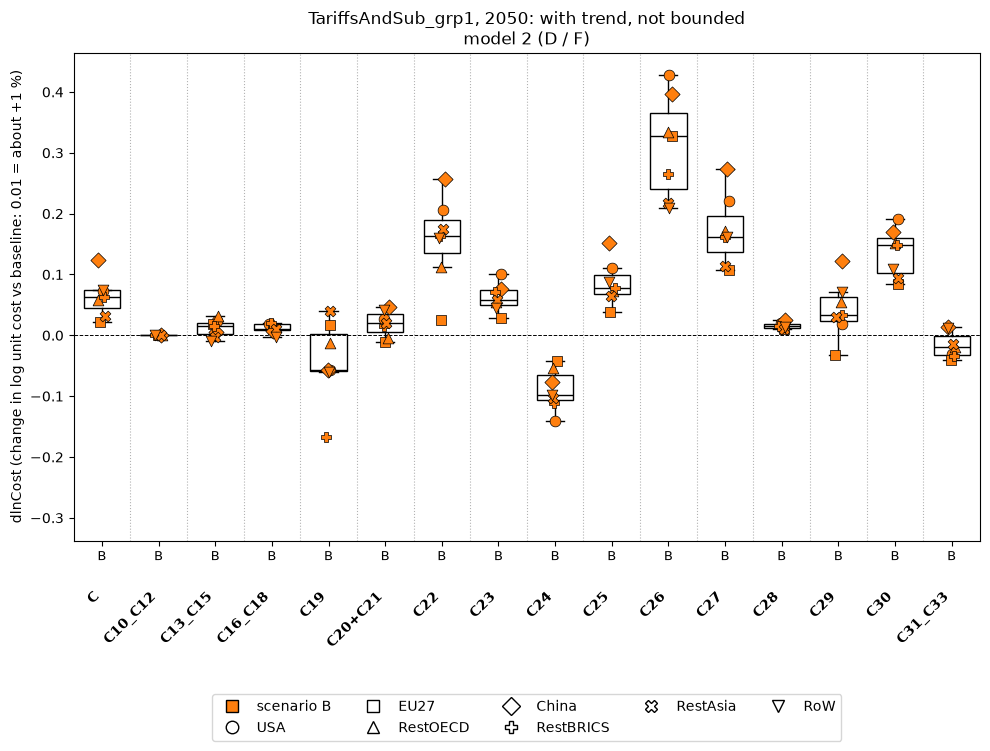

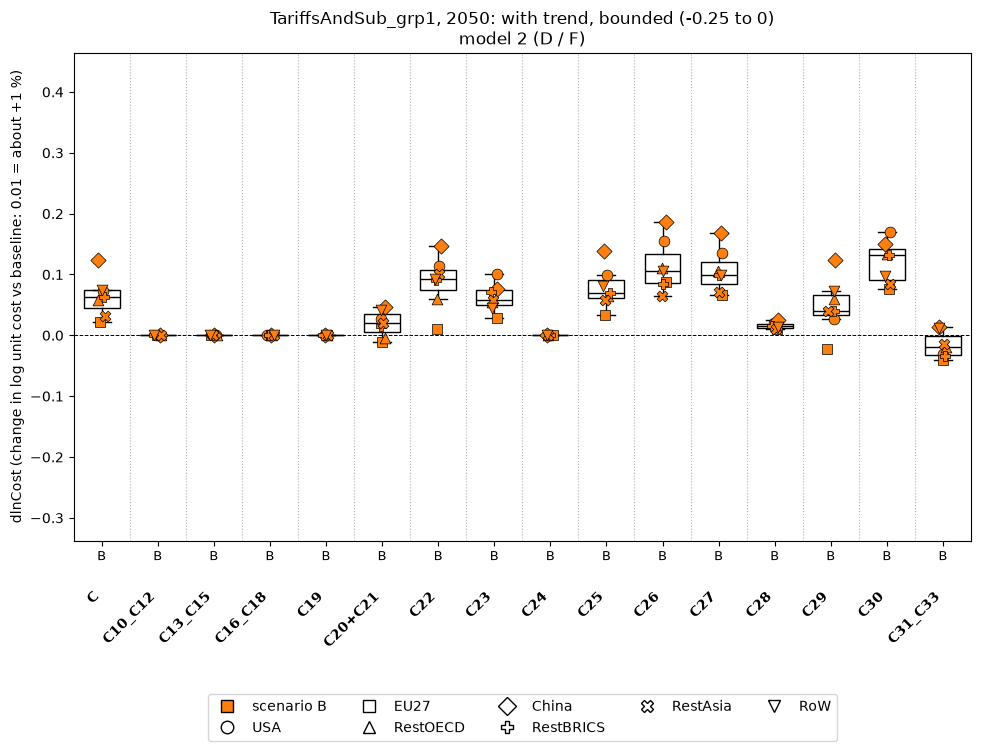

In [30]:
frames = {label: load_horizon(BASE, CONTENT, NEMESIS_SCENARIO, suffix, MODEL, PLOT_YEAR) for label, suffix in BETA_VARIANTS.items()}
frames = {label: d for label, d in frames.items() if d is not None}
if not frames:
    raise FileNotFoundError("no results file for any version of the betas: run choc_horizon first (see the cell above)")

# Plot the available A/B cases selected by choc_horizon.CASES, with a common vertical scale across beta variants.
scenarios_plot = [s for s in SCENARIOS if any(s in set(d["scenario"]) for d in frames.values())]
shown = pd.concat([d[d["sector"].isin(SECTORS) & d["bloc"].isin(BLOCS_TO_PLOT) & d["scenario"].isin(scenarios_plot)]["dlnCost"] for d in frames.values()])
margin = 0.05 * (shown.max() - shown.min())
ylim = (shown.min() - margin, shown.max() + margin)

for label, d in frames.items():
    suffix = BETA_VARIANTS[label]
    fig, ax = plot_choc(d, SECTORS, BLOCS_TO_PLOT, scenarios_plot, MODEL, title=f"{NEMESIS_SCENARIO}, {PLOT_YEAR}: {label}")
    ax.set_ylim(*ylim)
    export_graph((fig, ax), RESULTS_DIR + f"graphs/choc_dlnCost_{BASE}_{CONTENT}_{NEMESIS_SCENARIO}{suffix}_{PLOT_YEAR}_modele{MODEL}.png")
    plt.show()